[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cristhianbgf/urubamba-snow-ice-mapping/blob/main/notebooks/urubamba_nieve_hielo.ipynb)

# Nieve y hielo visible en la Cordillera Urubamba con Sentinel-2
### Pseudoetiquetas espectrales, validación espacial y evaluación contra contornos Landsat 2020

**Artículo computacional · Sentinel-2 L2A · cinco adquisiciones de 2020 · grilla de 20 m**

¿Mejora un mapa de nieve y hielo visible si se añaden relieve e iluminación, se revisan las reglas que generan las etiquetas automáticas y se cambia el clasificador? Los modelos se entrenan **sólo con pseudoetiquetas espectrales**: los contornos glaciares de referencia no se usan para ajustar nada y se leen únicamente al final, para puntuar los mapas ya congelados. El resumen numérico se genera más abajo a partir de las tablas de resultados.

In [1]:
import sys, os, subprocess
from pathlib import Path

# En Google Colab se clona el repositorio y se instala rasterio, que Colab no trae.
if "google.colab" in sys.modules:
    REPO = Path("/content/urubamba-snow-ice-mapping")
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/Cristhianbgf/urubamba-snow-ice-mapping", str(REPO)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
    os.chdir(REPO)

from IPython.display import Image, Markdown, display
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from urubamba import config as C, features
from urubamba.data import scene_folder

REENTRENAR = False  # True vuelve a ajustar y evaluar todos los modelos (unos minutos en CPU)
TABLAS, FIGURAS = C.RESULTS / "tables", C.FIGURES
faltan = [s for s in C.SCENES if not (scene_folder(s) / "SCL.tif").exists()]
faltan += [] if C.DEM_FILE.exists() else [C.DEM_FILE.name]
print("Insumos completos" if not faltan else (f"Faltan insumos: {faltan}. Las tablas y figuras guardadas se muestran igual; "
       "para reentrenar, ejecuta `python -m urubamba download` y baja el DEM como indica el README."))

def figura(nombre, ancho=1000):
    display(Image(filename=str(FIGURAS / f"{nombre}.png"), width=ancho))
    display(Markdown("*" + (FIGURAS / f"{nombre}.txt").read_text(encoding="utf-8") + "*"))

def num(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")

Insumos completos


## 1. Pregunta y antecedentes

La pregunta no es si la curva de entrenamiento se acerca a cero, sino si el mapa mejora en lugares que no se usaron al ajustar. Las ideas probadas vienen de trabajos recientes y se adaptan con los datos disponibles; no se reproducen sus redes ni sus cifras:

| Fuente | Idea | Cómo se usa aquí |
|---|---|---|
| [Diaconu et al., 2025 (DL4GAM)](https://doi.org/10.1029/2025EA004197) | Variables de relieve, separación geográfica y ensambles | Orientación, incidencia solar, rugosidad y ensamble de árboles; no se entrena su U-Net |
| [Barzegar et al., 2026 (CryoNet, prepublicación)](https://arxiv.org/abs/2605.21527) | Combinación de variables e importancia por grupos | NDGI, contexto multiescala y permutación agrupada |
| [Cheung y Thomson, 2025](https://doi.org/10.3390/rs17233872) | Entrenar clasificadores con pseudoetiquetas | Reglas espectrales en lugar de agrupamiento |
| [Aberle et al., 2025](https://tc.copernicus.org/articles/19/1675/2025/) | Evaluación con zonas excluidas y métricas de borde | Exclusión espacial, F1 de borde y distancias |
| [Taylor et al., 2022](https://doi.org/10.5285/d4dedc2d-1f7f-45c8-8b04-41b8b099cef9) | Contornos glaciares 2020 a partir de compuestos Landsat | Referencia externa, sólo para evaluar |

Las cifras publicadas por esos trabajos no son comparables con las de este cuaderno: cambian las clases, las regiones, las referencias y las particiones.

## 2. Datos y geoprocesamiento

Cuatro adquisiciones Sentinel-2 L2A de la estación seca de 2020 sirven para ajustar; la del 27-08-2020 es la imagen objetivo y nunca aporta etiquetas. Las bandas ópticas se promedian por bloques a una grilla de 20 m en EPSG:32718; la clasificación de escena (SCL) se toma por vecino más cercano y acepta los códigos 2, 4, 5, 6 y 11. El DEM es el ALOS PALSAR RTC `AP_27628_PLR_F6920_RT1` (ASF), promediado a la misma grilla.

,escena,uso,CRS,pixel_nativo_m
0,S2A_18LZL_20200529_1_L2A,ajuste,EPSG:32718,10.0
1,S2A_18LZL_20200618_0_L2A,ajuste,EPSG:32718,10.0
2,S2A_18LZL_20200718_0_L2A,ajuste,EPSG:32718,10.0
3,S2A_18LZL_20200807_1_L2A,ajuste,EPSG:32718,10.0
4,S2A_18LZL_20200827_1_L2A,objetivo,EPSG:32718,10.0


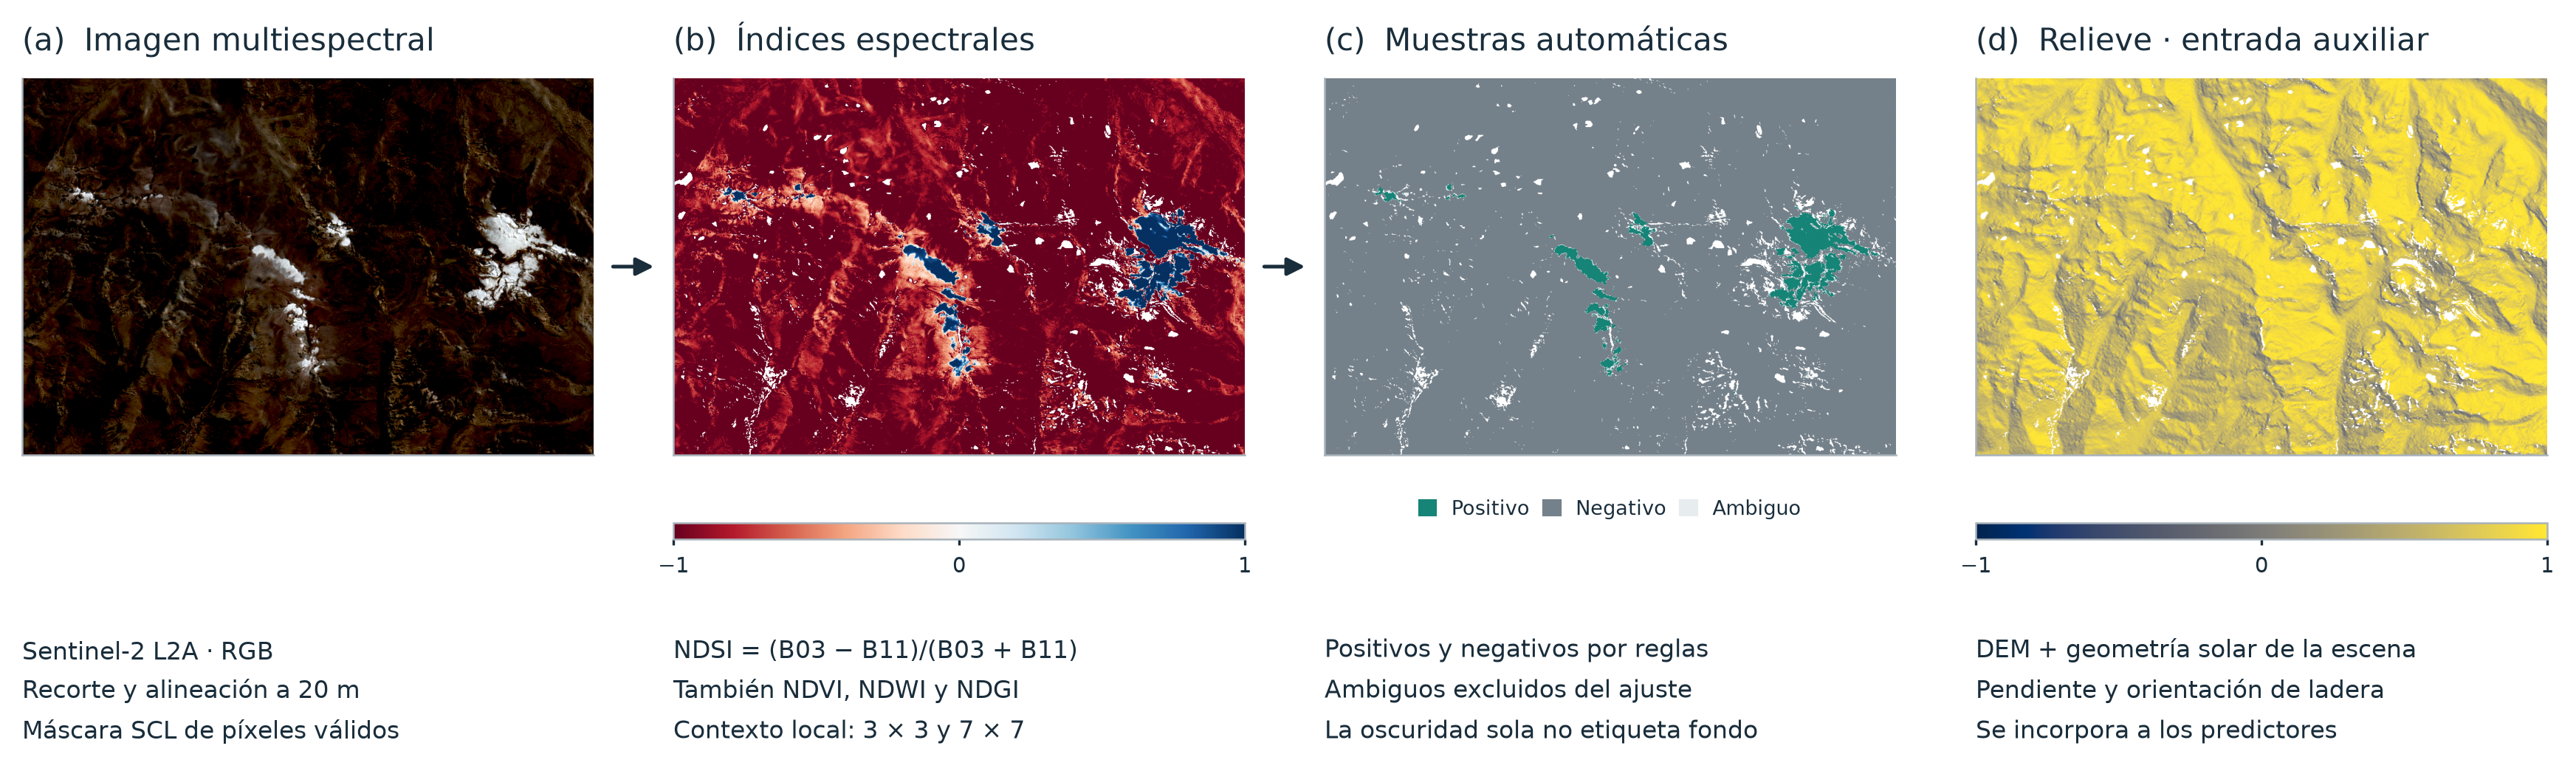

*Figura 1. Construcción de variables y pseudoetiquetas. (a–c) Reflectancias, índices y reglas de etiquetado; (d) DEM y geometría solar como entradas auxiliares. Las cuatro vistas muestran la escena objetivo del 27-08-2020 para explicar el procesamiento; sus pseudoetiquetas NO se usan para entrenar. La misma transformación se aplica a las cuatro fechas de ajuste y reúne 20 variables. La incidencia describe la iluminación local de la ladera, no sombras proyectadas ni una corrección radiométrica. El DEM promediado a 20 m no gana resolución efectiva. Norte arriba; recorte de 22 × 14,5 km.*

In [2]:
filas = []
for escena in C.SCENES:
    import rasterio
    banda = scene_folder(escena) / "B03.tif"
    if not banda.exists():  # sin insumos descargados (por ejemplo, en Colab)
        filas.append(dict(escena=escena, uso="objetivo" if escena == C.TARGET_SCENE else "ajuste",
                          CRS=C.CRS, pixel_nativo_m="sin descargar"))
        continue
    with rasterio.open(banda) as ds:
        filas.append(dict(escena=escena, uso="objetivo" if escena == C.TARGET_SCENE else "ajuste",
                          CRS=str(ds.crs), pixel_nativo_m=ds.res[0]))
display(pd.DataFrame(filas))
figura("01_geoprocesamiento")

## 3. Variables, pseudoetiquetas y diseño espacial

**Variables.** La base tiene 13: seis reflectancias, NDSI, NDVI, NDWI, elevación, pendiente y media y desviación de NDSI en 3 × 3. La versión completa añade 7: seno y coseno de la orientación, incidencia solar con la posición del sol de cada escena, desviación local del DEM, NDGI y media y desviación de NDSI en 7 × 7. La incidencia describe la iluminación de la ladera; no es una máscara de sombras proyectadas ni una corrección topográfica.

**Pseudoetiquetas.** Positivo: NDSI ≥ 0,55, rojo/SWIR ≥ 2 y NIR ≥ 0,15. Negativo base: NDSI ≤ 0,15 o NIR ≤ 0,08. Negativo prudente: sólo NDSI ≤ 0,15, para que un píxel oscuro no se etiquete como fondo por el solo hecho de ser oscuro. Lo ambiguo no entra al ajuste.

**Separación espacial.** El recorte se divide en tres sectores (oeste, centro, este). Cada modelo excluye su sector objetivo y 500 m de margen, con hasta 3 500 muestras por clase y fecha. Para elegir cuántas iteraciones usa el boosting se reserva además una partición interna de bloques de 3 km con 200 m de separación.

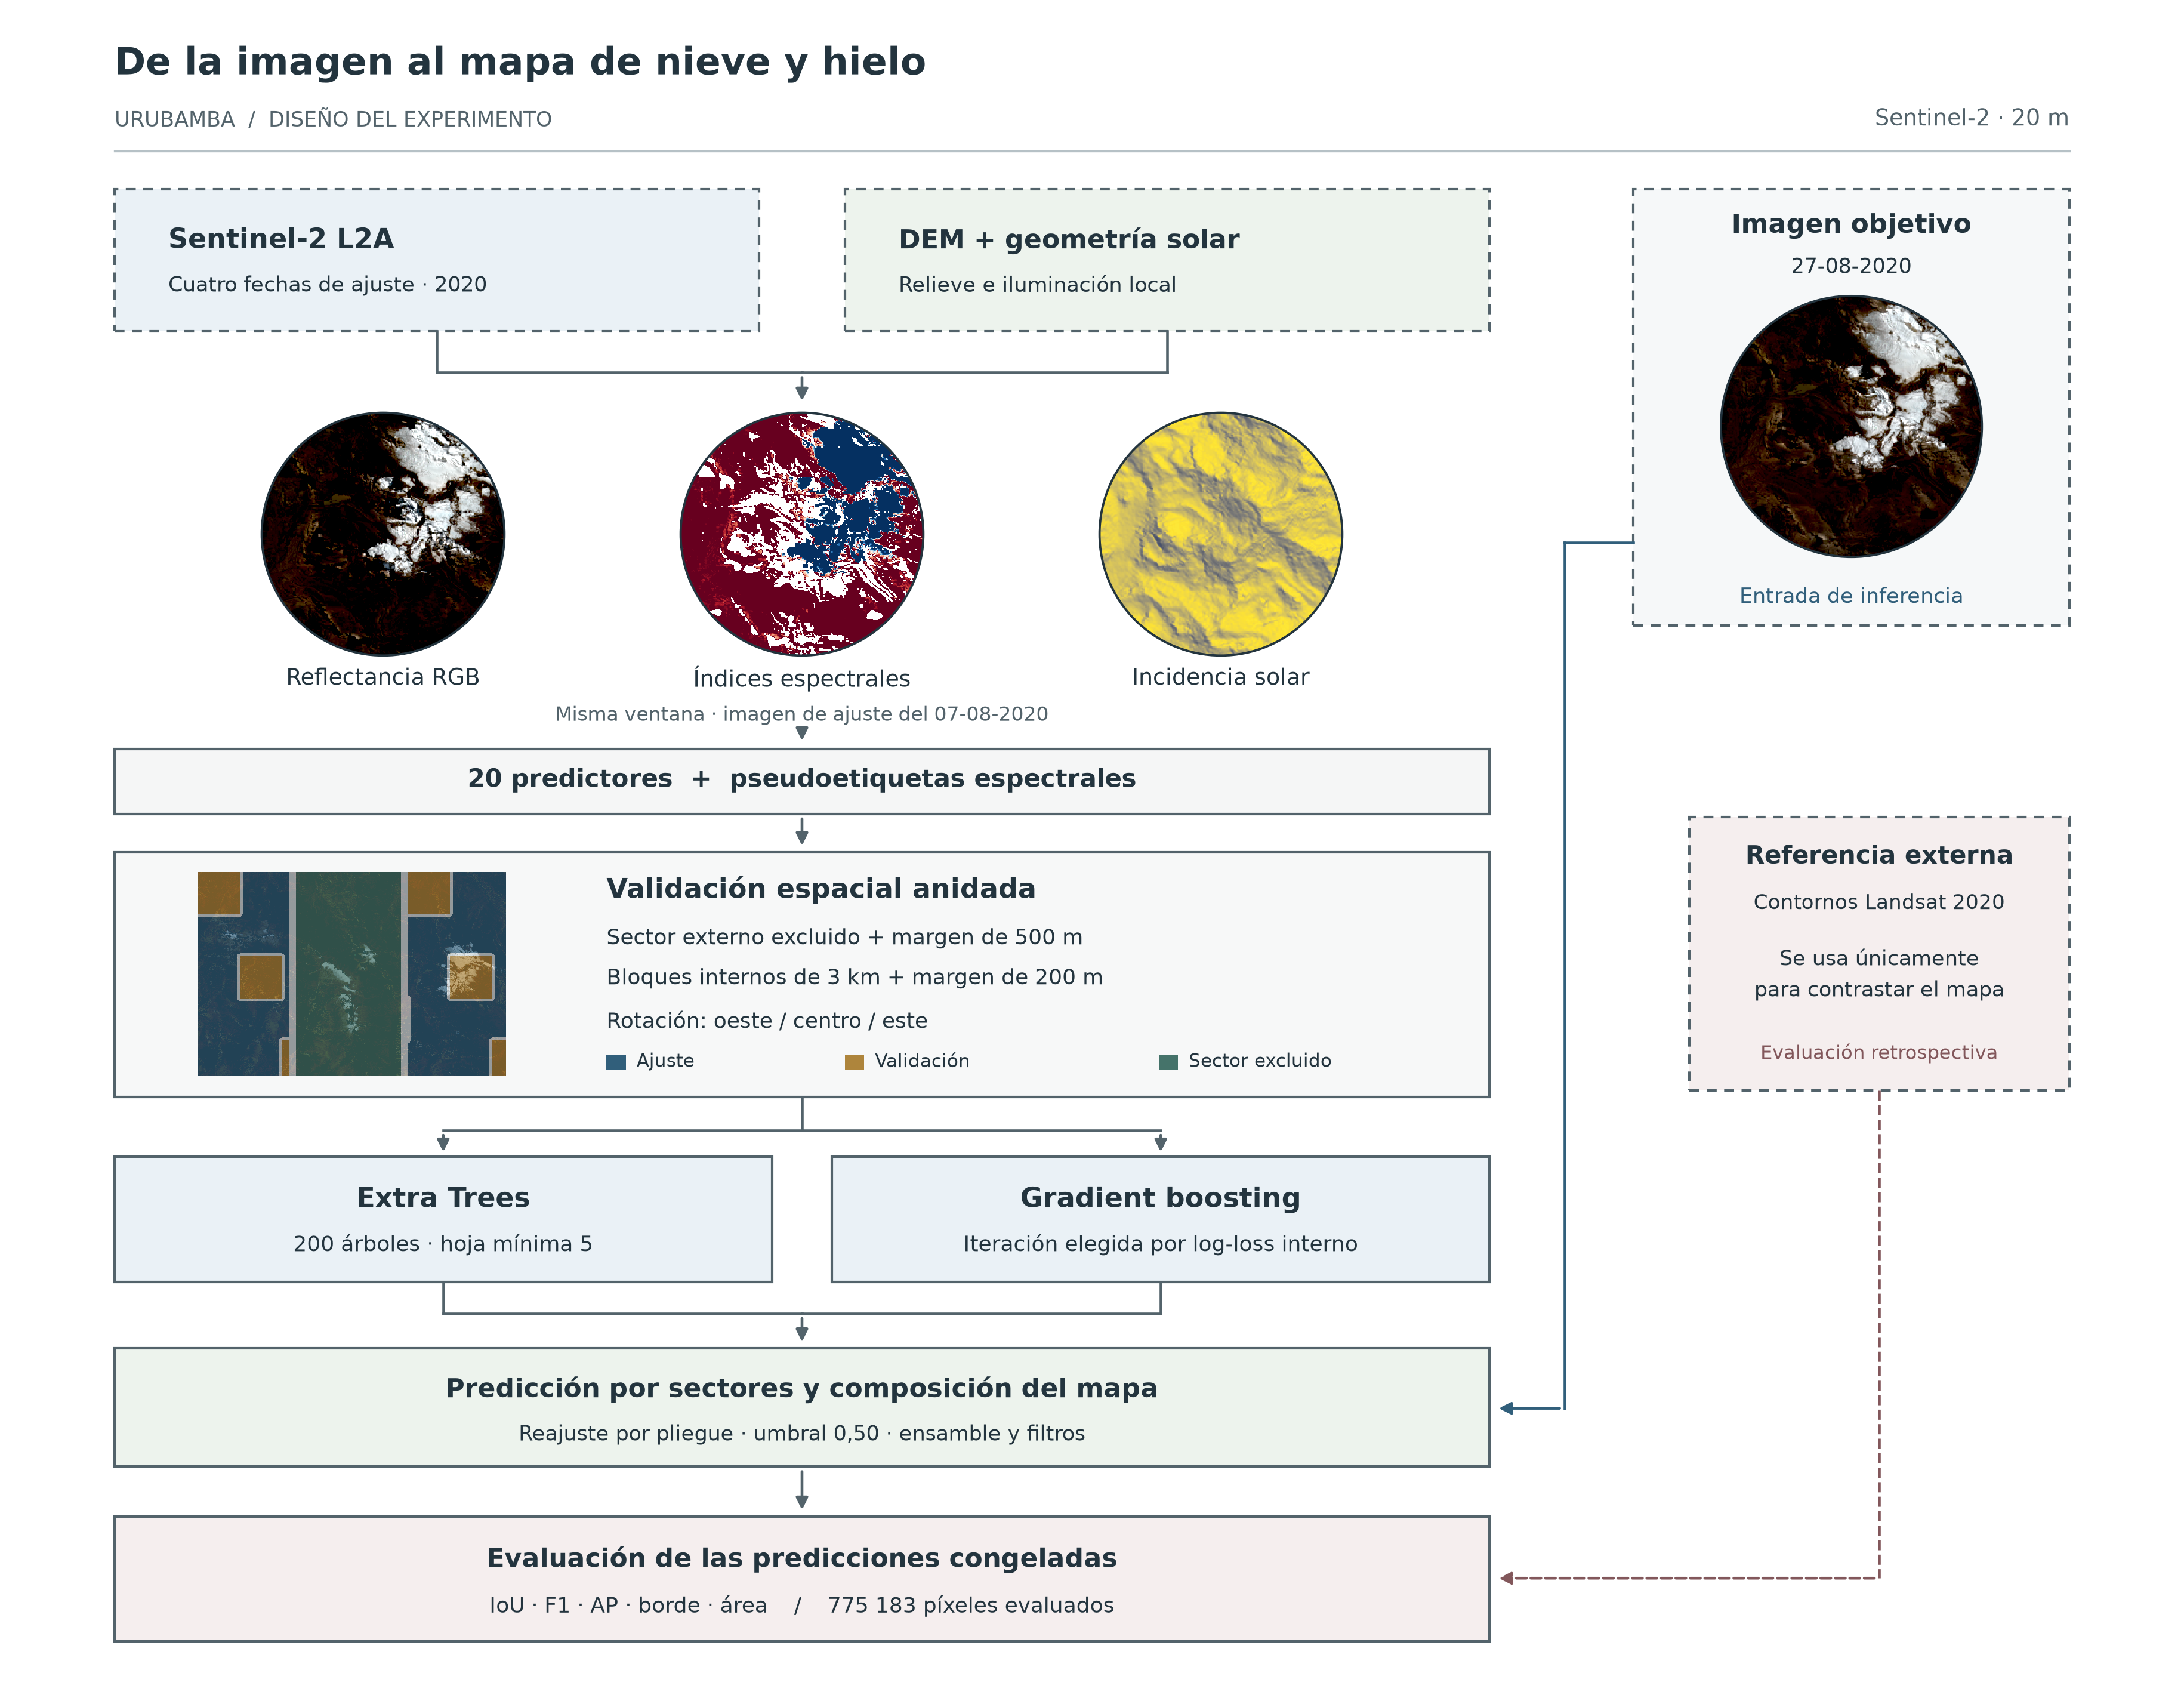

*Figura 2. Flujo del experimento. Los recortes circulares proceden de la adquisición de ajuste del 07-08-2020. La imagen objetivo del 27-08-2020 entra sólo para inferencia. Se generan pseudoetiquetas espectrales en cuatro fechas de ajuste y se extraen 20 predictores. La partición ilustrada excluye el sector central y 500 m de margen; los bloques internos de validación miden 3 km, con separación de 200 m. Se rota el sector externo para formar el mapa completo. El mínimo log-loss interno elige la iteración del boosting; después se reajusta con todas las muestras permitidas. Los contornos Landsat sólo intervienen en la evaluación. Los colores del mapa de partición indican asignaciones geográficas, no clases. Norte arriba; paneles a distintas escalas.*

,n,predictor,en la base
0,1,B02,True
1,2,B03,True
2,3,B04,True
3,4,B08,True
4,5,B11,True
5,6,B12,True
6,7,NDSI,True
7,8,NDVI,True
8,9,NDWI,True
9,10,Elevación,True


**Extra Trees:** `{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.7}`  
**Boosting:** `{'max_iter': 240, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0}`

In [3]:
figura("02_diseno_entrenamiento")
display(pd.DataFrame({"n": range(1, len(features.FULL) + 1), "predictor": features.FULL,
                      "en la base": [i < len(features.BASE) for i in range(len(features.FULL))]}))
display(Markdown(f"**Extra Trees:** `{C.EXTRA_TREES}`  \n**Boosting:** `{C.BOOSTING}`"))

## 4. Entrenamiento

| Método | Variables | Negativos | Clasificador |
|---|---|---|---|
| Extra Trees base | 13 | base | Extra Trees |
| Extra Trees + relieve | 20 | base | Extra Trees |
| Semillas prudentes | 20 | prudentes | Extra Trees |
| Gradient boosting | 20 | prudentes | HistGradientBoosting |
| Ensamble | — | — | promedio de Extra Trees base y semillas prudentes |
| NDSI | — | — | regla NDSI ≥ 0,40 y NIR ≥ 0,11, sin entrenamiento |

Cada puntaje se corta en 0,50 y se guarda tal cual y con un filtro espacial (mayoría 3 × 3 donde todos los vecinos son válidos y eliminación de manchas menores de 1 ha). Extra Trees base y semillas prudentes tienen además una variante con filtro guiado por NDSI. La configuración completa se escribe en `results/configuration.json` antes de evaluar, y los mapas quedan congelados con su huella SHA-256.

,sector,selected_iteration,inner_train,inner_val,validation_logloss
0,0,170,28000,9600,0.001554
1,1,198,26812,9600,0.002885
2,2,235,28000,5472,0.000357


label                negativos  positivos
metodo       sector                      
ET_base      0           14000      14000
             1           14000      14000
             2           14000      14000
ET_prudente  0           14000      14000
             1           14000      14000
             2           14000      14000
ET_relieve   0           14000      14000
             1           14000      14000
             2           14000      14000
HGB_prudente 0           14000      14000
             1           14000      14000
             2           14000      14000

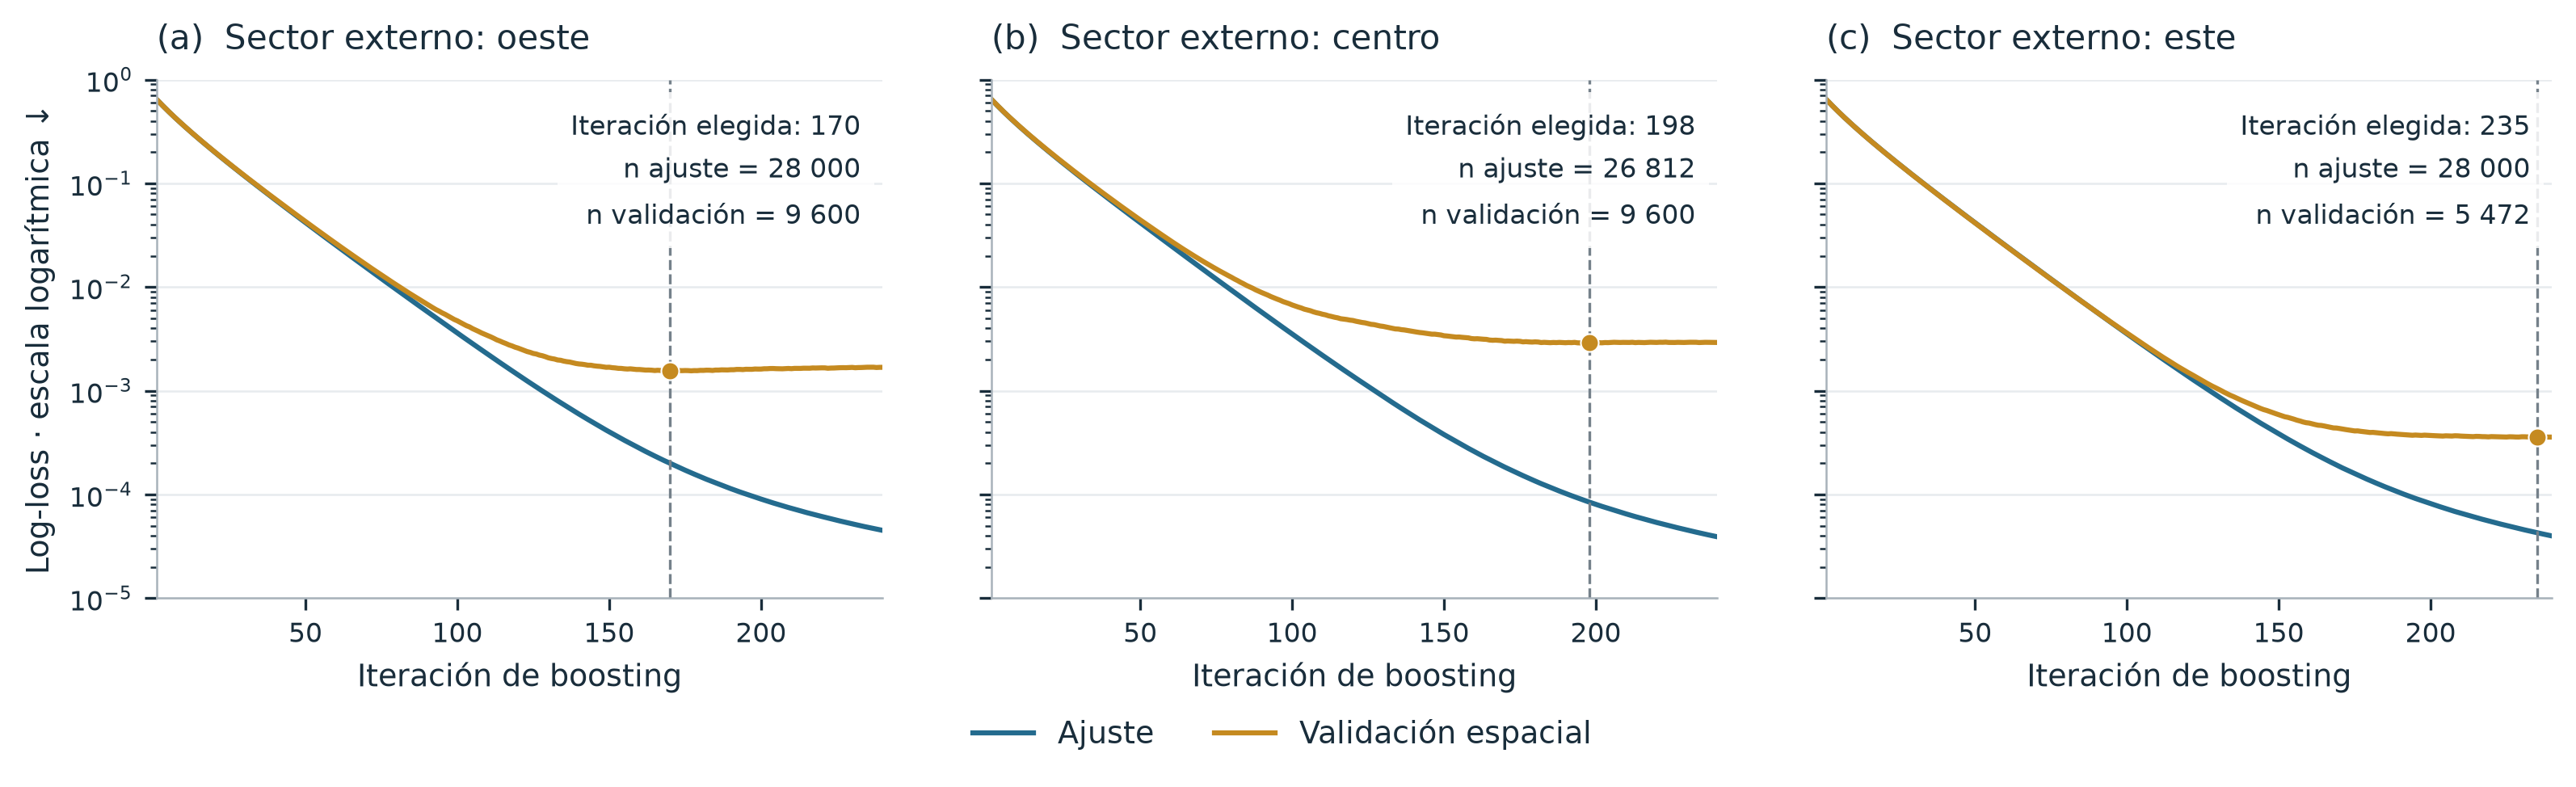

*Figura 3. Pérdida por iteración del HistGradientBoostingClassifier en escala logarítmica. Azul: ajuste; ocre: validación en bloques geográficos excluidos. El mínimo de validación elige la iteración (170, 198, 235 para oeste, centro y este) antes del reajuste en toda el área permitida. Las tres curvas son tres modelos distintos, no repeticiones. Miden fidelidad a las pseudoetiquetas, no exactitud glaciar: los píxeles ambiguos no entran en esta pérdida.*

In [4]:
if REENTRENAR:
    from threadpoolctl import threadpool_limits
    from urubamba.models import fit
    from urubamba.evaluate import evaluate
    with threadpool_limits(limits=C.N_JOBS):
        fit(); evaluate()
    from urubamba.figures import main as figuras; figuras()
display(pd.read_csv(TABLAS / "seleccion_iteraciones.csv"))
m = pd.read_csv(TABLAS / "muestras.csv")
display(m.groupby(["metodo", "sector", "label"])["used"].sum().unstack("label").rename(columns={0: "negativos", 1: "positivos"}))
figura("03_curvas_entrenamiento")

**Cómo leer las curvas.** Una pérdida de validación muy baja dice que el modelo reproduce las reglas de pseudoetiquetado en los píxeles de alta confianza. No dice que delimite bien los glaciares: los casos ambiguos quedaron fuera de esa pérdida y sí están en la evaluación externa.

## 5. Evaluación externa

Sólo aquí se leen los contornos de Taylor et al. (2022). Se evalúan todos los píxeles válidos de la imagen objetivo. La referencia es un compuesto anual Landsat: tiene otra fecha efectiva y otra resolución, así que no es una verdad terreno a 20 m. Los intervalos salen de 2 000 remuestras pareadas de bloques de 1 km y no corrigen la elección del método destacado.

Píxeles evaluados: 775 183 · referencia: 8,08 km²


,metodo,iou,iou_lo,iou_hi,f1,precision,recall,mcc,f1_borde_20m,distancia_p95_m,sesgo_area_km2
11,HGB_prudente_filtro,0.8083,0.7157,0.8662,0.8940,0.8582,0.9329,0.8919,0.7641,120.0000,0.7024
6,ET_prudente_filtro,0.8078,0.7182,0.8634,0.8937,0.8618,0.9279,0.8913,0.7823,116.6190,0.6196
1,Ensamble_ET_filtro,0.8076,0.7190,0.8629,0.8936,0.8665,0.9223,0.8911,0.7796,141.4214,0.5200
3,ET_base_filtro,0.8054,0.7171,0.8605,0.8922,0.8685,0.9173,0.8896,0.7763,145.6022,0.4536
9,ET_relieve_filtro,0.8048,0.7162,0.8607,0.8918,0.8660,0.9192,0.8893,0.7765,152.3155,0.4960
7,ET_prudente_guiado,0.8020,0.7117,0.8590,0.8901,0.8591,0.9235,0.8877,0.7883,178.8854,0.6060
13,NDSI_filtro,0.8002,0.7105,0.8561,0.8890,0.8720,0.9066,0.8861,0.7651,180.6092,0.3208
4,ET_base_guiado,0.7984,0.7085,0.8539,0.8879,0.8661,0.9109,0.8851,0.7853,178.8854,0.4180
10,HGB_prudente,0.7940,0.7020,0.8531,0.8852,0.8449,0.9295,0.8830,0.7663,222.8854,0.8080
5,ET_prudente,0.7892,0.6990,0.8467,0.8822,0.8452,0.9225,0.8798,0.7669,241.6609,0.7384


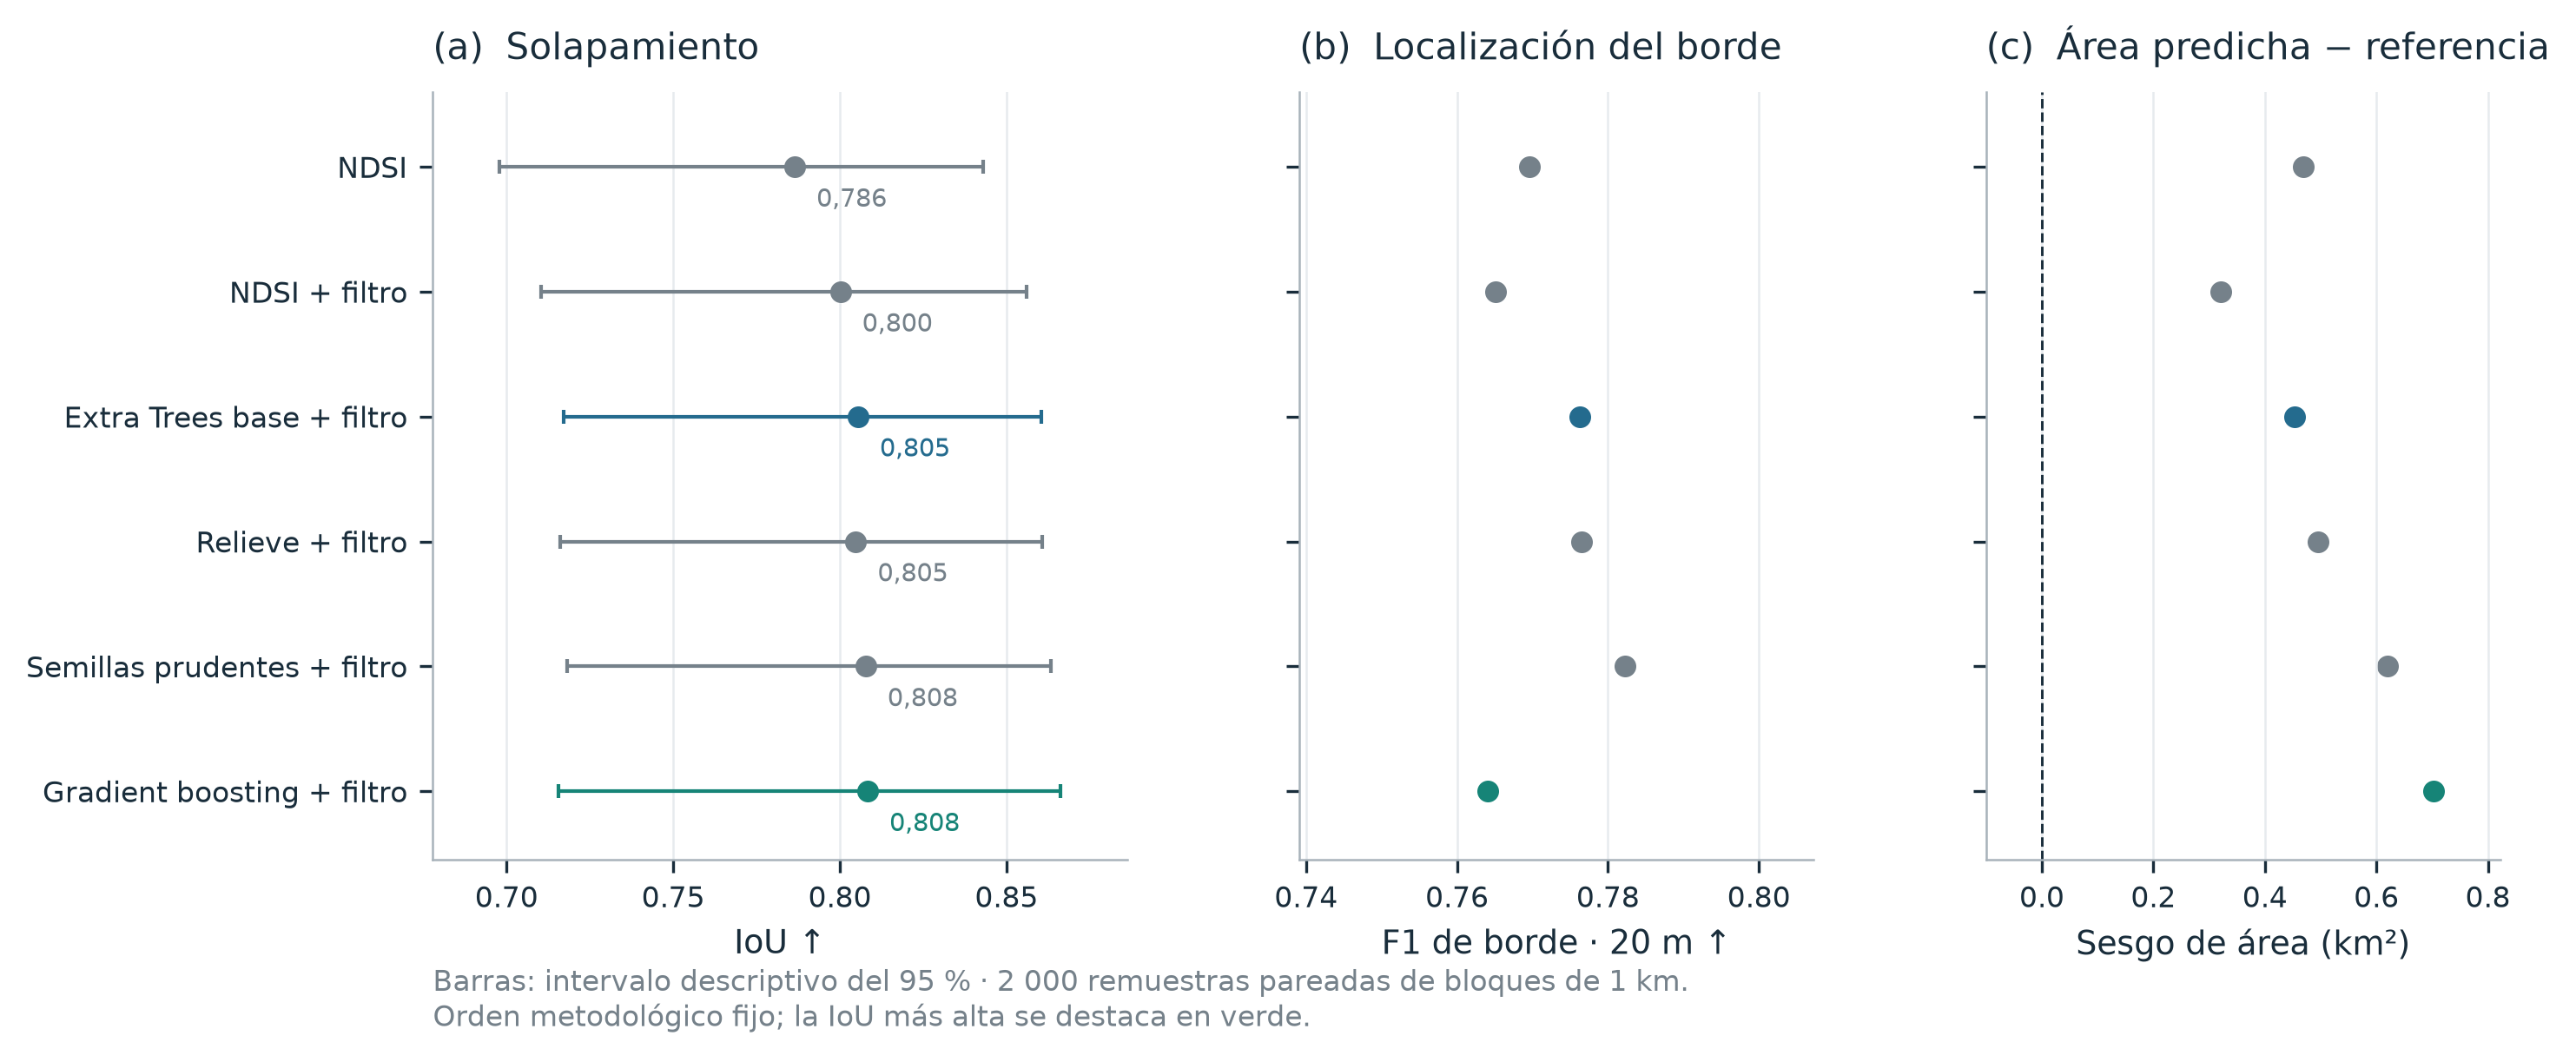

*Figura 4. Comparación sobre los mismos 775 183 píxeles de 20 m. Se muestra una selección por familia; la tabla completa incluye todos los candidatos, también los que empeoran. IoU y F1 de borde son métricas distintas: más área coincidente no implica mejor límite. Ejes ampliados para distinguir diferencias pequeñas. El candidato destacado se elige después de ver la evaluación y sus intervalos no corrigen esa selección.*

,pregunta,candidato,control,delta_iou,lo,hi
0,Añadir relieve y contexto,ET_relieve,ET_base,0.00105,-0.00003,0.00233
1,Semillas negativas prudentes,ET_prudente,ET_relieve,0.00202,-0.00075,0.00453
2,Boosting frente a Extra Trees,HGB_prudente,ET_prudente,0.00486,-0.00043,0.00993
3,Filtro espacial,ET_prudente_filtro,ET_prudente,0.01859,0.01308,0.02628
4,Ensamble frente a la base,Ensamble_ET_filtro,ET_base_filtro,0.00219,0.00029,0.00440
5,Guiado frente a mayoría,ET_base_guiado,ET_base_filtro,-0.00700,-0.01098,-0.00365


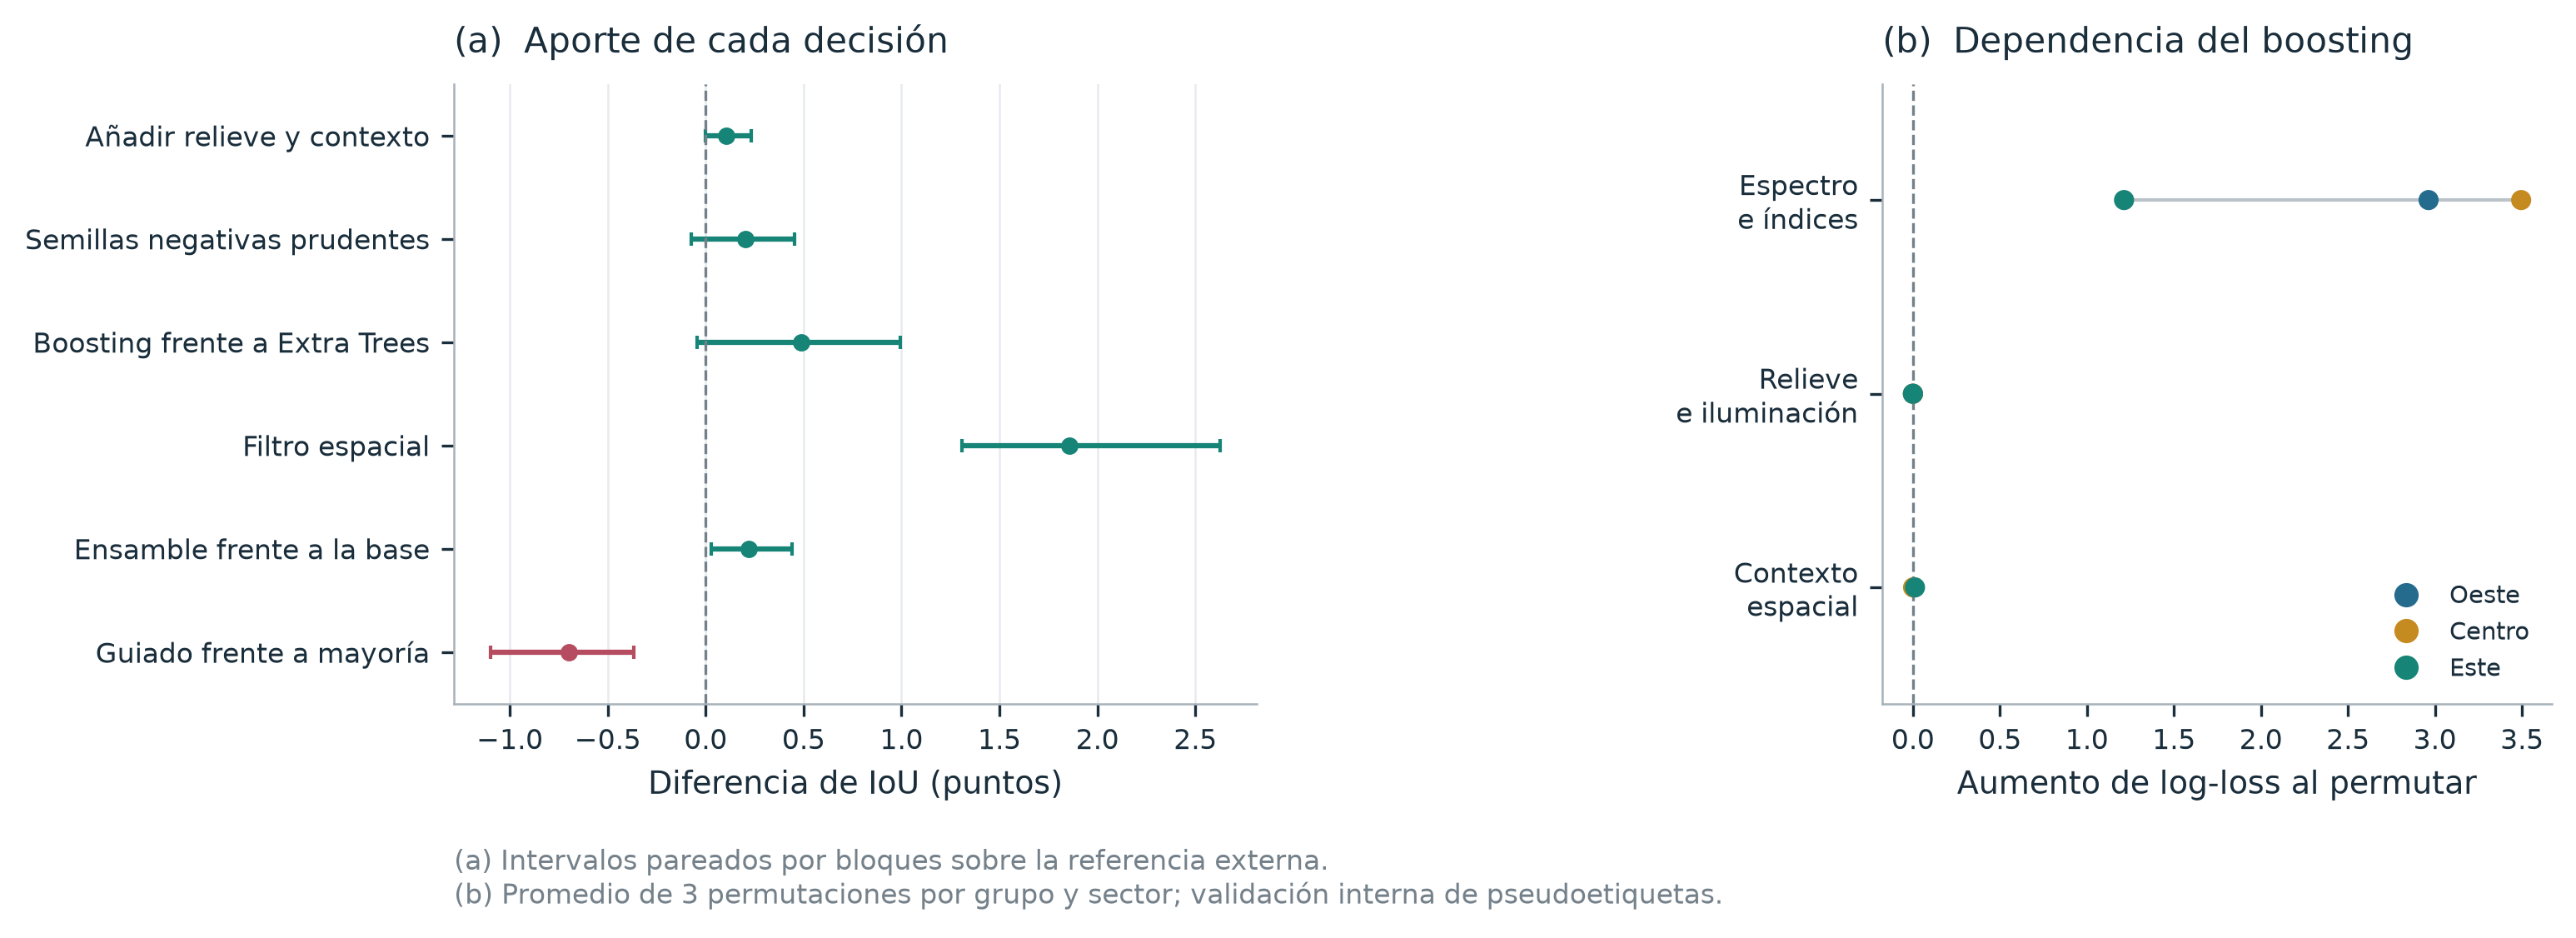

*Figura 5. Ablaciones e importancia por grupos. La primera ablación añade a la vez relieve, NDGI y contexto 7 × 7, así que no separa el efecto de cada variable. Las semillas prudentes eliminan la regla que convertía en negativo todo píxel oscuro. El filtro guiado conserva discontinuidades de NDSI y usa el mismo mínimo de componente (1 ha), sin mayoría 3 × 3. Importancia: cambio de log-loss al permutar conjuntamente cada grupo, sólo en la validación interna; no es causalidad ni aporte a la exactitud externa.*

In [5]:
t = pd.read_csv(TABLAS / "metricas.csv")
cols = ["metodo", "iou", "iou_lo", "iou_hi", "f1", "precision", "recall", "mcc", "f1_borde_20m", "distancia_p95_m", "sesgo_area_km2"]
display(t[cols].sort_values("iou", ascending=False).round(4))
print(f"Píxeles evaluados: {t.n_pixeles.iloc[0]:,} · referencia: {num(t.referencia_km2.iloc[0], 2)} km²".replace(",", " ", 1))
figura("04_comparacion_controlada")
display(pd.read_csv(TABLAS / "ablaciones.csv").round(5))
figura("05_ablaciones_e_importancia")

## 6. ¿Dónde se equivocan los mapas?

Las tres ventanas, una por sector, se fijaron antes de evaluar. Sólo se colorean los desacuerdos con la referencia; donde coinciden se sigue viendo la imagen.

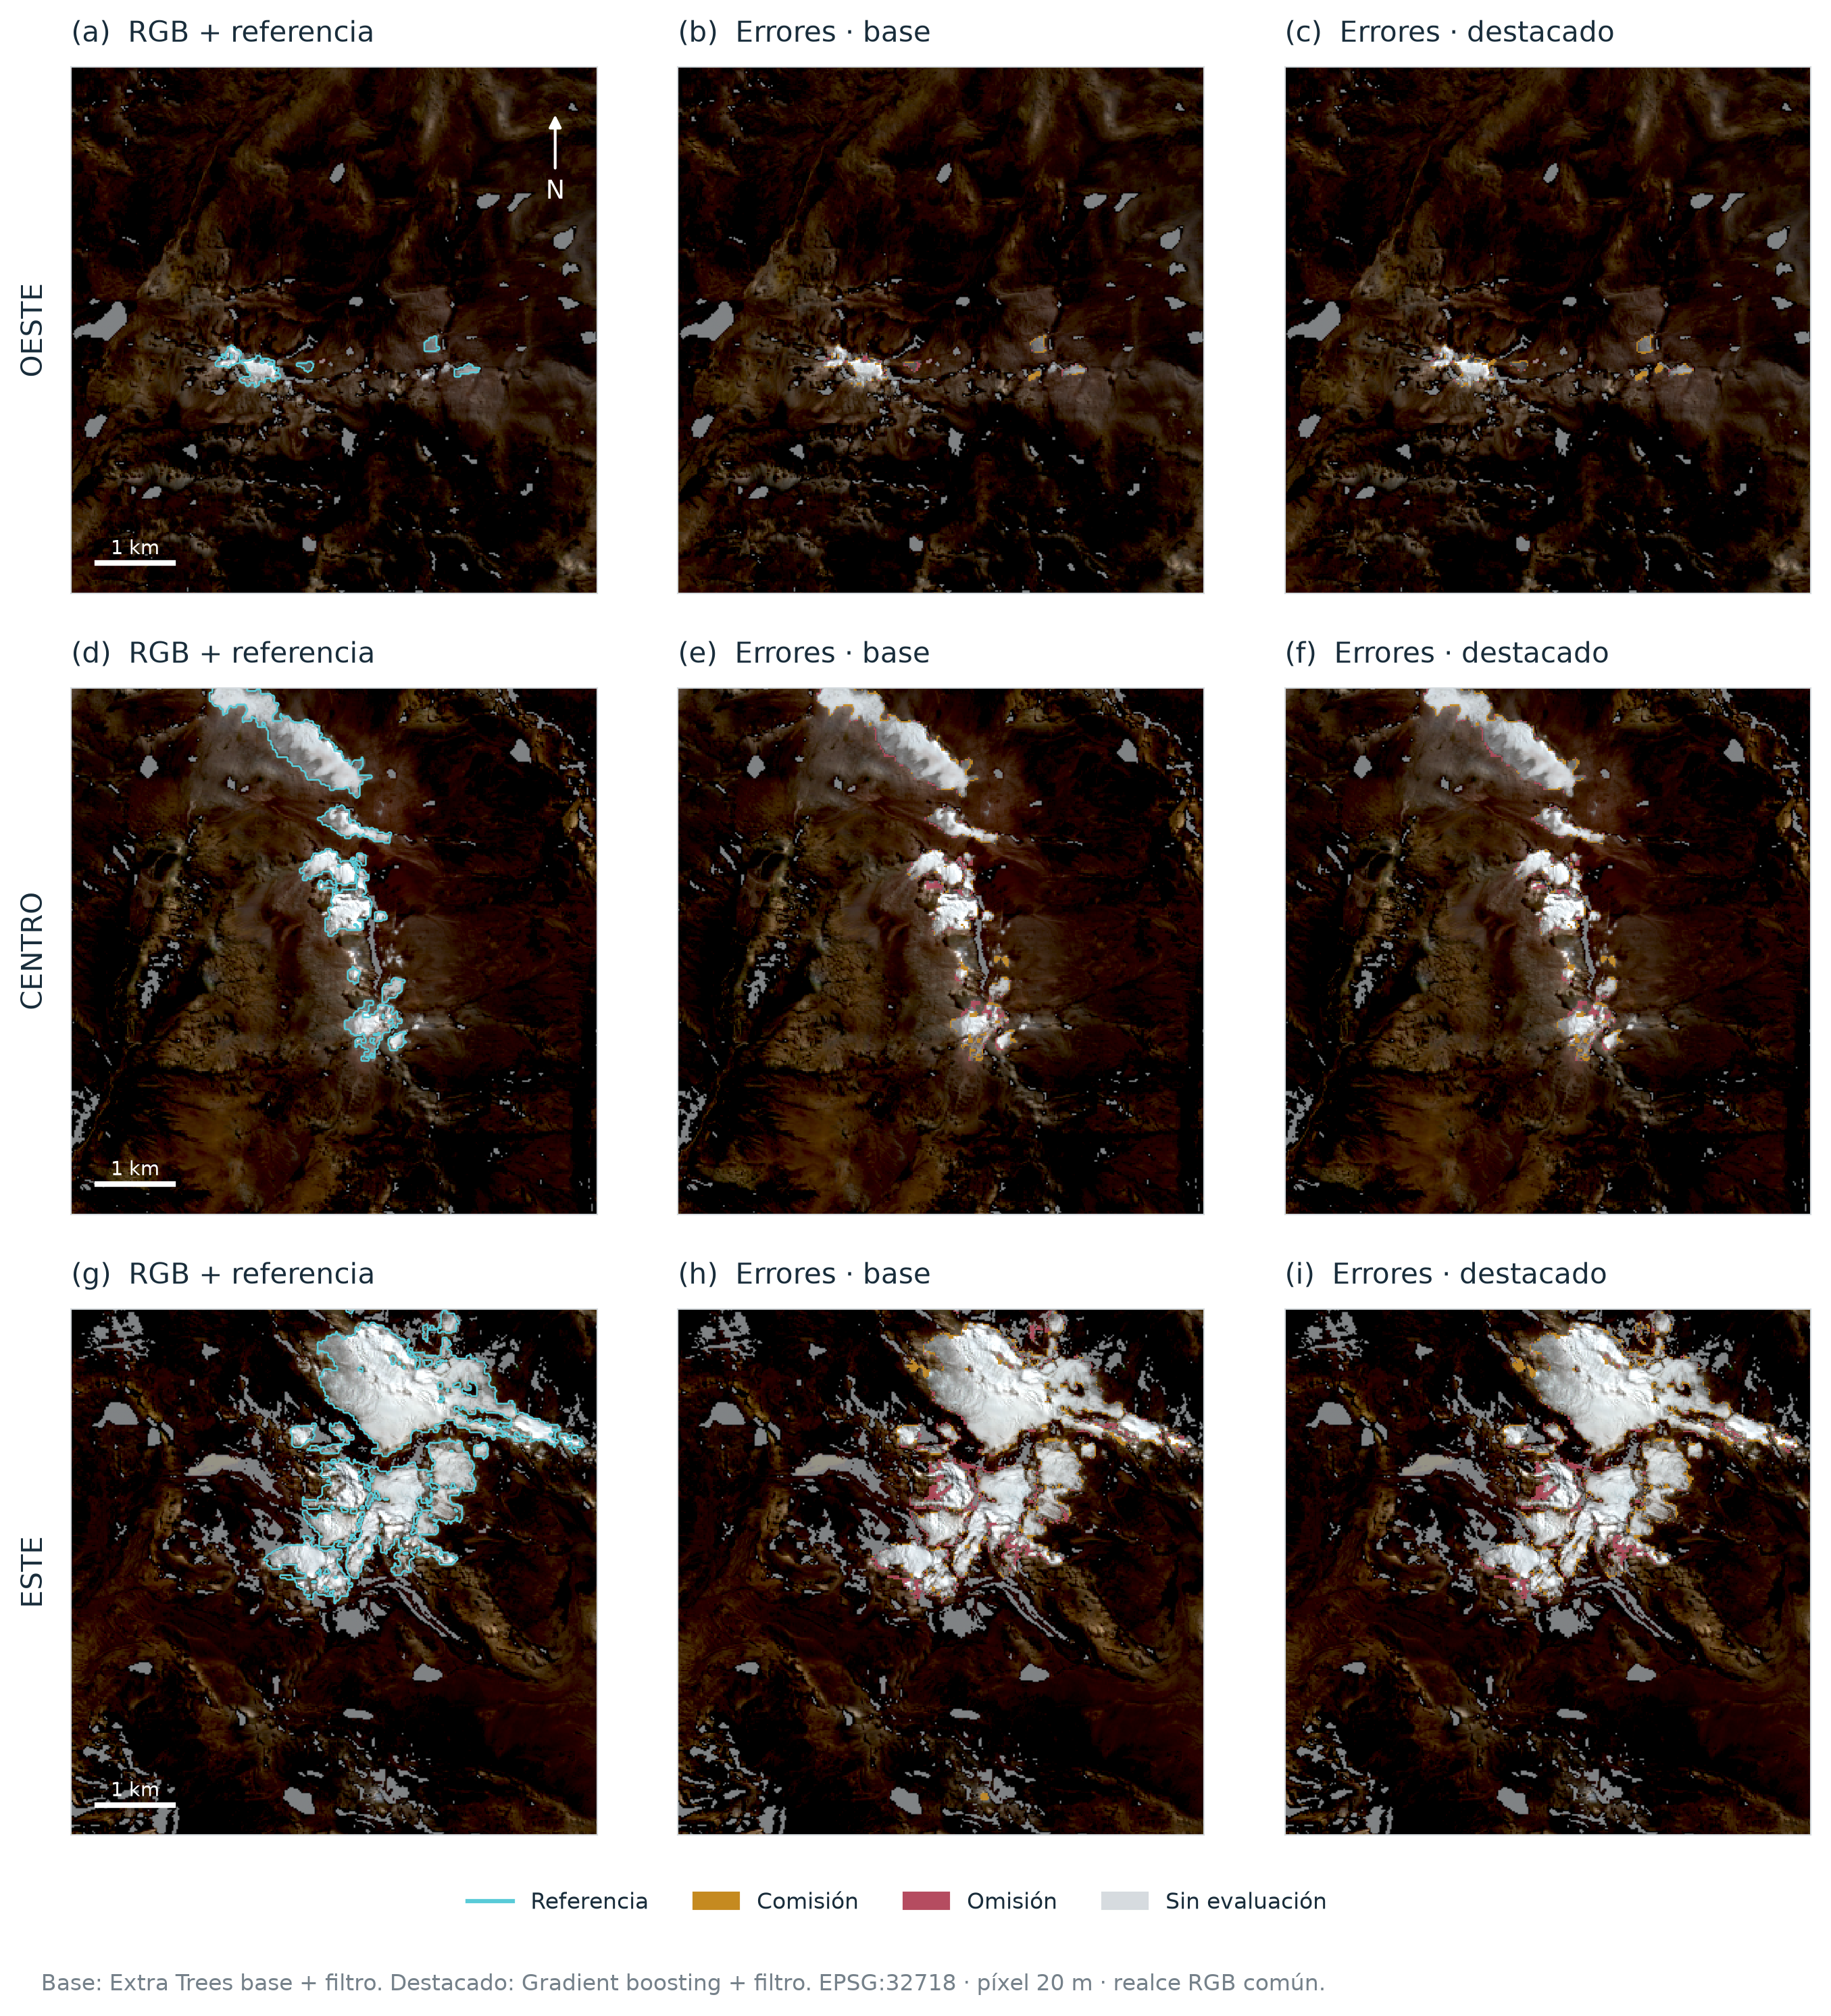

*Figura 6. Ventanas de 7 × 7 km, una por sector, fijadas antes de evaluar. Límites en km UTM 18S: oeste E 808–815 / N 8537–8544; centro E 815–822 / N 8531–8538; este E 822,5–829,5 / N 8532,5–8539,5. Primera columna: imagen y contorno Landsat de referencia; segunda y tercera: sólo desacuerdos, con la imagen visible donde coinciden. Naranja: comisión; magenta: omisión. Realce RGB común = clip(reflectancia/0,9, 0, 1)^0,55. El compuesto Landsat tiene otro soporte temporal y otra resolución efectiva. Norte de grilla arriba.*

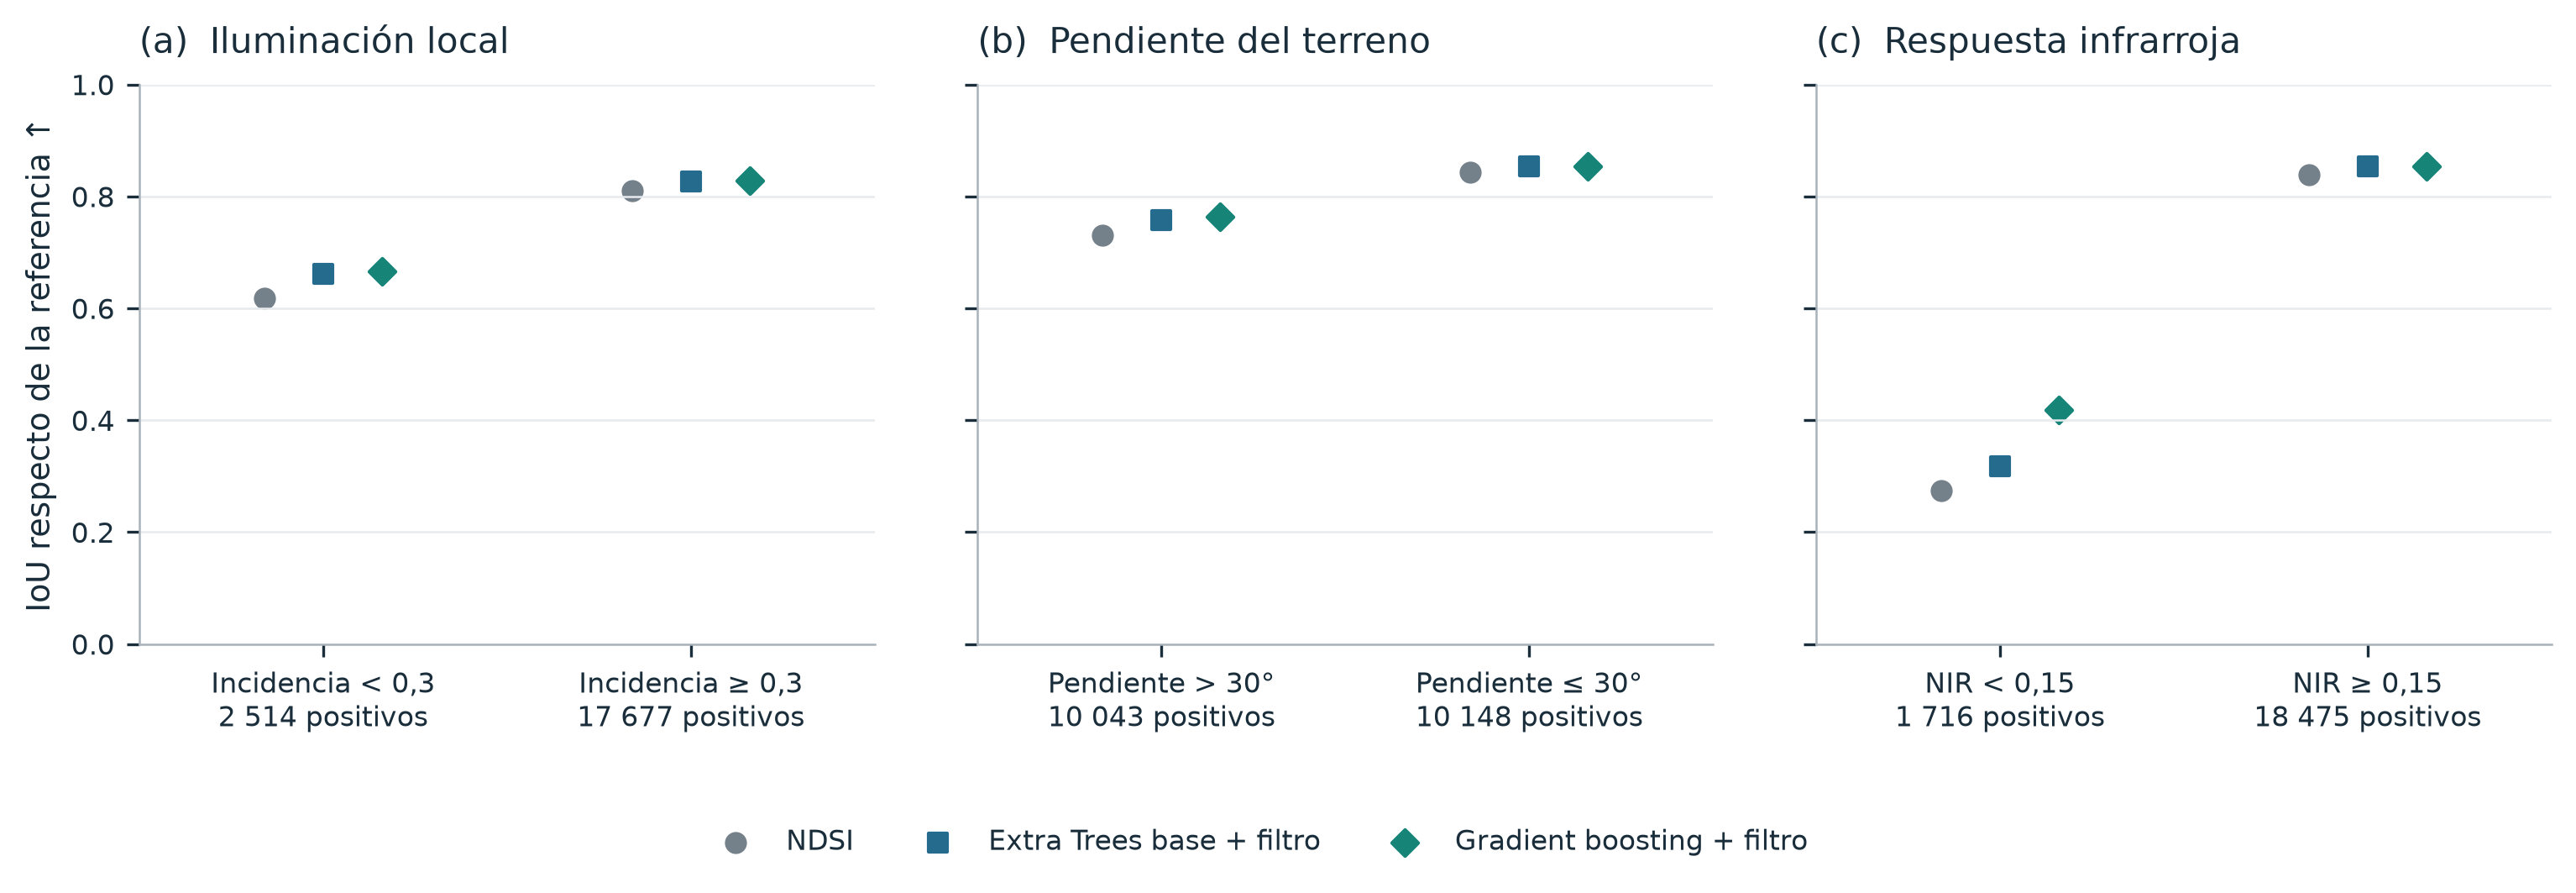

*Figura 7. Rendimiento según terreno y señal de la imagen. Cada par divide los mismos píxeles evaluados; las tres familias se superponen y no se suman entre sí. Se indica el número de positivos de referencia para leer con cuidado los grupos pequeños. Incidencia < 0,3 significa iluminación local baja, no una máscara completa de sombras. Los umbrales no se reajustaron con estos resultados.*

metodo,ET_base_filtro,HGB_prudente_filtro,NDSI
regimen,,,
Centro,0.6933,0.6887,0.6781
Este,0.8619,0.8700,0.8447
"Incidencia < 0,3",0.6621,0.6654,0.6176
"Incidencia ≥ 0,3",0.8263,0.8289,0.8109
"NIR < 0,15",0.3177,0.4185,0.2746
"NIR ≥ 0,15",0.8540,0.8537,0.8383
Oeste,0.7390,0.7130,0.6558
Pendiente > 30°,0.7573,0.7638,0.7304
Pendiente ≤ 30°,0.8541,0.8536,0.8438


In [6]:
destacado = (TABLAS / "candidato_destacado.txt").read_text().strip()
figura("06_evidencia_espacial", 900)
figura("07_condiciones_dificiles")
r = pd.read_csv(TABLAS / "regimenes.csv")
display(r[r.metodo.isin(["NDSI", "ET_base_filtro", destacado])].pivot(index="regimen", columns="metodo", values="iou").round(4))

## 7. Puntajes continuos

Con tan pocos positivos, la exactitud global puede ocultar fallos. La average precision (AP) resume la relación precisión–recall en todos los umbrales; no es una probabilidad calibrada. El umbral de los mapas se mantuvo en 0,50.

,metodo,AP,prevalencia
0,ET_base,0.88405,0.02605
1,ET_relieve,0.88311,0.02605
2,ET_prudente,0.88301,0.02605
3,HGB_prudente,0.91465,0.02605
4,Ensamble_ET,0.88876,0.02605
5,NDSI,0.83169,0.02605


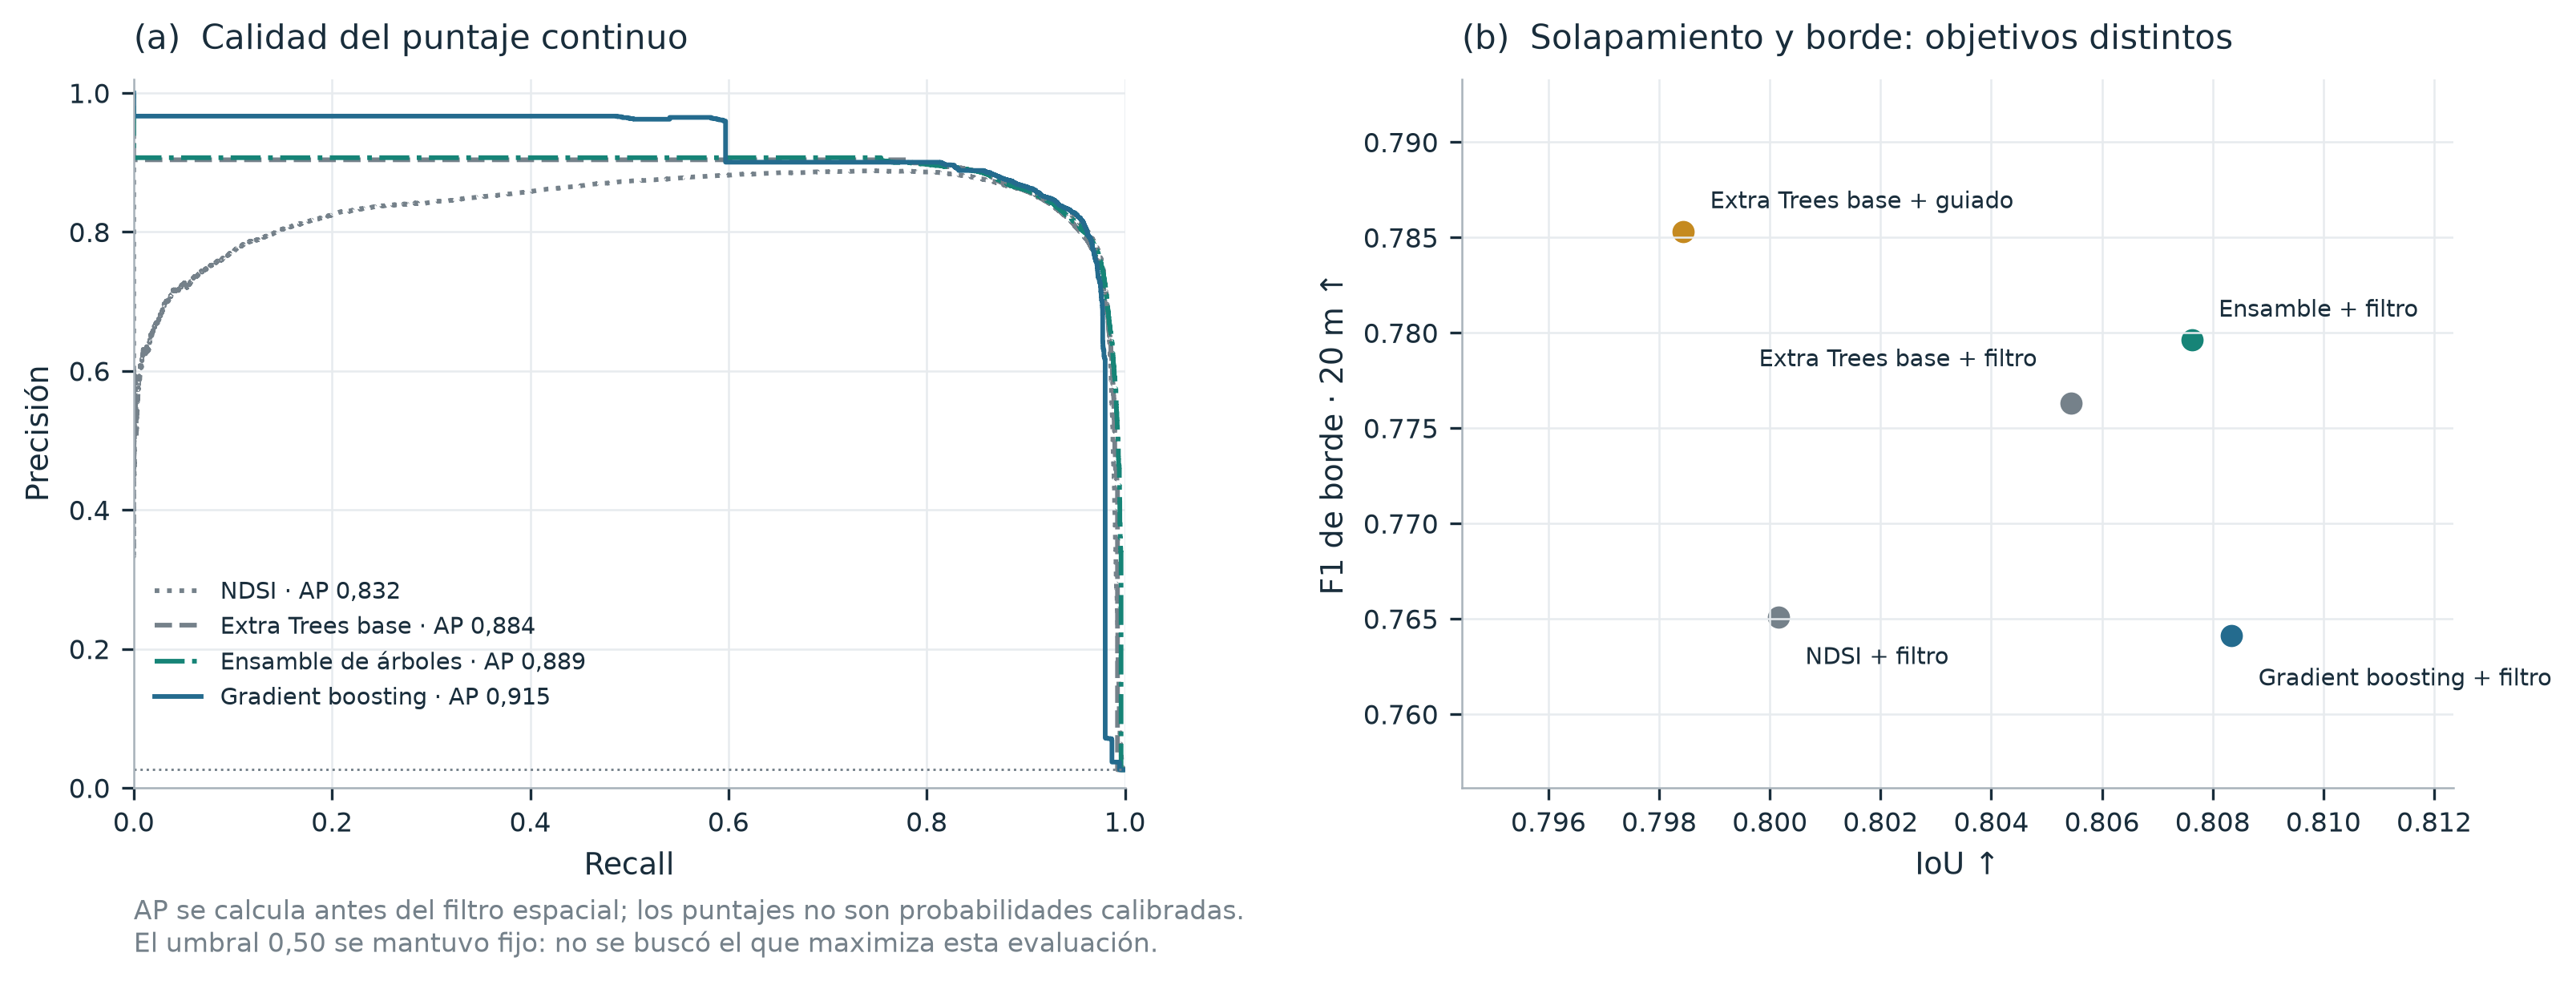

*Figura 8. (a) Curvas precisión–recall completas y escalonadas; su integral coincide con la average precision (AP). Prevalencia positiva 2,60 %; la línea punteada horizontal es el AP de un puntaje aleatorio. (b) Solapamiento frente a límite a 20 m, con ejes ampliados. Una AP mayor indica que el puntaje ordena mejor los píxeles frente a esta referencia; no garantiza una mejora equivalente con el umbral fijo.*

In [7]:
display(pd.read_csv(TABLAS / "average_precision.csv").round(5))
figura("08_puntajes_y_compromisos")

## 8. Resultados en cifras

In [8]:
t = pd.read_csv(TABLAS / "metricas.csv").set_index("metodo")
a = pd.read_csv(TABLAS / "ablaciones.csv").set_index("candidato")
ap = pd.read_csv(TABLAS / "average_precision.csv").set_index("metodo").AP
from urubamba.figures import LABELS
d = destacado
pts = lambda x: num(100 * x, 3)
texto = f"""
* **Solapamiento.** La IoU más alta es la de **{LABELS[d]}** ({num(t.loc[d,'iou'],4)}), frente a {num(t.loc['ET_base_filtro','iou'],4)} de Extra Trees base con filtro y {num(t.loc['NDSI_filtro','iou'],4)} de la regla NDSI con filtro. Esa ventaja sale de mirar la evaluación, así que es exploratoria.
* **Cada decisión por separado** (diferencia de IoU en puntos, intervalo pareado del 95 %):
  añadir relieve {pts(a.loc['ET_relieve','delta_iou'])} [{pts(a.loc['ET_relieve','lo'])}; {pts(a.loc['ET_relieve','hi'])}];
  semillas prudentes {pts(a.loc['ET_prudente','delta_iou'])} [{pts(a.loc['ET_prudente','lo'])}; {pts(a.loc['ET_prudente','hi'])}];
  boosting frente a Extra Trees {pts(a.loc['HGB_prudente','delta_iou'])} [{pts(a.loc['HGB_prudente','lo'])}; {pts(a.loc['HGB_prudente','hi'])}];
  filtro espacial {pts(a.loc['ET_prudente_filtro','delta_iou'])} [{pts(a.loc['ET_prudente_filtro','lo'])}; {pts(a.loc['ET_prudente_filtro','hi'])}];
  ensamble frente a la base {pts(a.loc['Ensamble_ET_filtro','delta_iou'])} [{pts(a.loc['Ensamble_ET_filtro','lo'])}; {pts(a.loc['Ensamble_ET_filtro','hi'])}].
  Cuando el intervalo incluye cero, la mejora no es concluyente.
* **Puntaje continuo.** La AP del boosting es {num(ap['HGB_prudente'])}, frente a {num(ap['ET_base'])} de Extra Trees base y {num(ap['NDSI'])} del NDSI continuo.
* **Bordes.** El filtro guiado lleva el F1 de borde a 20 m a {num(t.loc['ET_base_guiado','f1_borde_20m'])} (base con mayoría: {num(t.loc['ET_base_filtro','f1_borde_20m'])}), pero baja la IoU {pts(-a.loc['ET_base_guiado','delta_iou'])} puntos [{pts(-a.loc['ET_base_guiado','hi'])}; {pts(-a.loc['ET_base_guiado','lo'])}]. Con semillas prudentes, el guiado llega a {num(t.loc['ET_prudente_guiado','f1_borde_20m'])}, el F1 de borde más alto del experimento. Ningún método gana en todas las métricas.
"""
display(Markdown(texto))


* **Solapamiento.** La IoU más alta es la de **Gradient boosting + filtro** (0,8083), frente a 0,8054 de Extra Trees base con filtro y 0,8002 de la regla NDSI con filtro. Esa ventaja sale de mirar la evaluación, así que es exploratoria.
* **Cada decisión por separado** (diferencia de IoU en puntos, intervalo pareado del 95 %):
  añadir relieve 0,105 [-0,003; 0,233];
  semillas prudentes 0,202 [-0,075; 0,453];
  boosting frente a Extra Trees 0,486 [-0,043; 0,993];
  filtro espacial 1,859 [1,308; 2,628];
  ensamble frente a la base 0,219 [0,029; 0,440].
  Cuando el intervalo incluye cero, la mejora no es concluyente.
* **Puntaje continuo.** La AP del boosting es 0,915, frente a 0,884 de Extra Trees base y 0,832 del NDSI continuo.
* **Bordes.** El filtro guiado lleva el F1 de borde a 20 m a 0,785 (base con mayoría: 0,776), pero baja la IoU 0,700 puntos [0,365; 1,098]. Con semillas prudentes, el guiado llega a 0,788, el F1 de borde más alto del experimento. Ningún método gana en todas las métricas.


## 9. Límites

* La referencia ya es conocida y es un compuesto anual: la comparación es retrospectiva y mezcla error del mapa con diferencias de fecha y resolución. Para confirmar mejoras hace falta otra referencia, cercana a la fecha de la imagen y reservada sólo para evaluar, que incluya sombras, nieve estacional, bordes y hielo con detritos.
* La supervisión viene de reglas espectrales sencillas. El relieve no recibe una señal que le enseñe los casos que esas reglas excluyen; por eso añadirlo apenas cambia el resultado, y la importancia por grupos mide dependencia de las reglas, no causalidad física.
* El clasificador mapea nieve y hielo visibles. No delimita hielo cubierto por detritos, no mide pérdida glaciar ni masa, y una sola fecha de prueba no permite hablar de tendencias.
* Las métricas pueden variar con otras versiones de las bibliotecas; las usadas constan en `requirements.txt`.